In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

IMG = 128

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.3,
    brightness_range=[0.7, 1.3],
    horizontal_flip=True,
    fill_mode="nearest")

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    r"C:\Users\Prince\Downloads\archive (1)\training_set\training_set",
    target_size=(IMG, IMG), batch_size=32, class_mode='binary')

test_generator = test_datagen.flow_from_directory(
    r"C:\Users\Prince\Downloads\archive (1)\test_set\test_set",
    target_size=(IMG, IMG), batch_size=32, class_mode='binary', shuffle=False)

model = models.Sequential([layers.Input(shape=(IMG, IMG, 3))])

for f in [32, 64, 128, 256]:
    model.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(2))

model.add(layers.GlobalAveragePooling2D())
model.add(layers.Dense(128, activation="relu"))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(1, activation="sigmoid"))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
]

history = model.fit(train_generator, validation_data=test_generator, epochs=60, callbacks=callbacks)

model.save("model_scratch.keras")
import json
json.dump(history.history, open("history_scratch.json", "w"))

Found 8005 images belonging to 2 classes.
Found 2023 images belonging to 2 classes.
Epoch 1/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - accuracy: 0.5605 - loss: 0.7305 - val_accuracy: 0.5002 - val_loss: 1.0088 - learning_rate: 0.0010
Epoch 2/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 360s 1s/step - accuracy: 0.5955 - loss: 0.6752 - val_accuracy: 0.6154 - val_loss: 0.6439 - learning_rate: 0.0010
Epoch 3/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 382s 2s/step - accuracy: 0.6222 - loss: 0.6485 - val_accuracy: 0.5645 - val_loss: 0.8254 - learning_rate: 0.0010
Epoch 4/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 362s 1s/step - accuracy: 0.6309 - loss: 0.6417 - val_accuracy: 0.6011 - val_loss: 0.7227 - learning_rate: 0.0010
Epoch 5/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.6571 - loss: 0.6201 - val_accuracy: 0.6204 - val_loss: 0.6396 - learning_rate: 0.0010
Epoch 6/60
251/251 ━━━━━━━━━━━━━━━━━━━━ 356s 1s/step - accuracy: 0.6843 - loss: 0.5994 - val_accuracy: 0.6891 - val_loss: 0.6485 - learning_rate: 0.001

KeyboardInterrupt: 

In [2]:
model.save("model_scratch.keras")

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image
import tensorflow as tf

In [12]:
def get_last_conv_name(model):
    return [l.name for l in model.layers if isinstance(l, tf.keras.layers.Conv2D)][-1]

def gradcam(model, img_array, conv_name):
    x = tf.convert_to_tensor(img_array)
    with tf.GradientTape() as tape:
        for layer in model.layers:
            x = layer(x)
            if layer.name == conv_name:
                conv_out = x
        preds = x
        score = preds[:, 0]
        if float(preds[0, 0]) < 0.5:
            score = 1 - score
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    heat = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    heat = tf.maximum(heat, 0)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy(), float(preds[0, 0])

In [14]:
import numpy as np
import matplotlib.cm as cm
from PIL import Image

def overlay(pil_img, heat, alpha=0.4):
    heat_img = Image.fromarray(np.uint8(255 * heat)).resize(pil_img.size, Image.BILINEAR)
    colored = cm.jet(np.array(heat_img) / 255.0)[..., :3]
    base = np.array(pil_img.convert("RGB")) / 255.0
    return np.clip((1 - alpha) * base + alpha * colored, 0, 1)

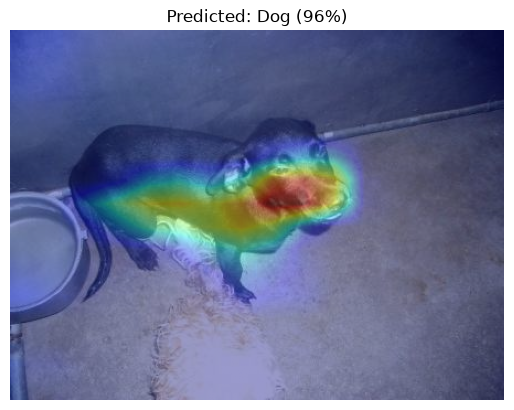

In [18]:
pil = Image.open(r"C:\Users\Prince\Downloads\archive (1)\test_set\test_set\dogs\dog.4976.jpg").convert("RGB")
arr = np.array(pil.resize((128, 128)), dtype="float32") / 255.0
arr = np.expand_dims(arr, 0)

heat, score = gradcam(model, arr, get_last_conv_name(model))

label = "Dog" if score > 0.5 else "Cat"
conf = score if score > 0.5 else 1 - score
plt.imshow(overlay(pil, heat)); plt.axis("off")
plt.title(f"Predicted: {label} ({conf*100:.0f}%)")
plt.show()

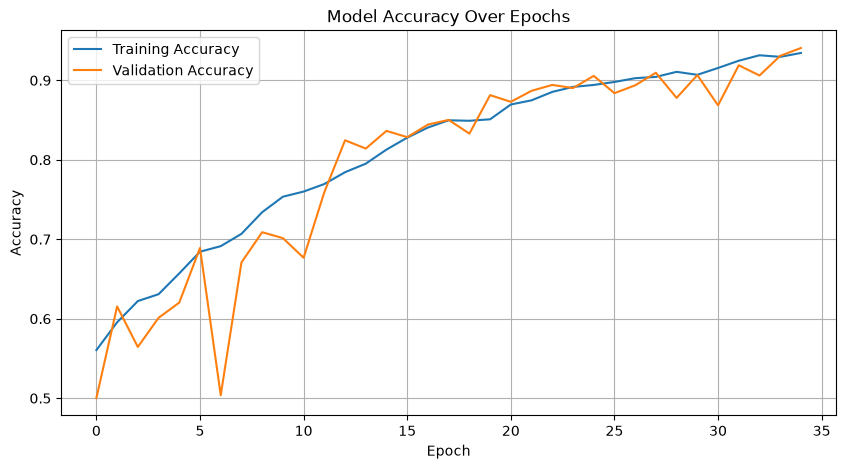

In [19]:
import matplotlib.pyplot as plt

# Get training history
history = model.history.history

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [22]:
acc = history['accuracy']
val_acc = history['val_accuracy']

loss = history['loss']
val_loss = history['val_loss']

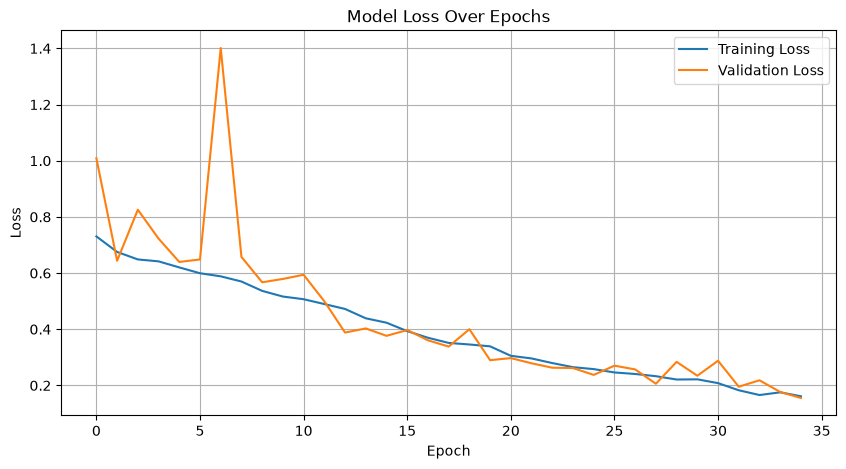

In [23]:
# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

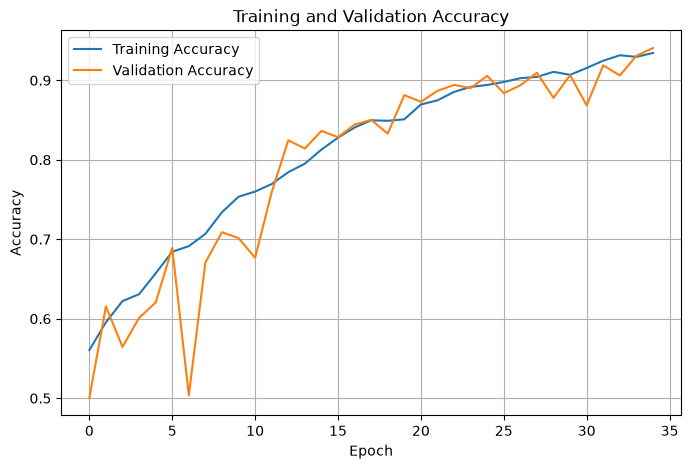

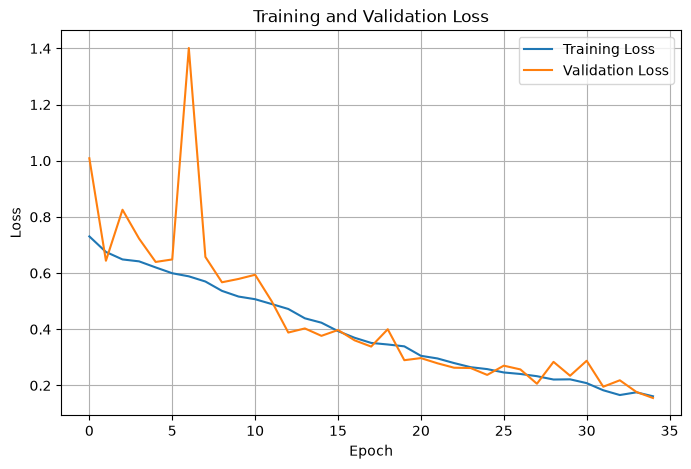

In [24]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure(figsize=(8, 5))
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot Loss
plt.figure(figsize=(8, 5))
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()
